In [1]:
# STFT FROM SCRATCH
# import
import numpy as np
from scipy.signal import stft as scipy_stft
import matplotlib.pyplot as plt

In [2]:
def compute_hop(nperseg, hop_fraction=0.25):
    """
    Calcule la taille du 'hop' (déplacement en échantillons) et renvoie aussi le recouvrement.

    Paramètres
    ----------
    nperseg : int
        Taille de la fenêtre en échantillons (doit être >= 1).
    hop_fraction : float
        Fraction du nperseg correspondant au hop.
        - Doit être strictement entre 0.0 et 1.0 (exclu).
        - hop_fraction = hop / nperseg.
        - Exemple : hop_fraction=0.25 -> hop = 0.25*nperseg -> overlap = 0.75 (75% recouvrement).

    Retour
    ------
    hop : int
        Nombre d'échantillons de déplacement entre trames (>= 1 et <= nperseg).
    overlap : float
        Fraction de recouvrement entre 0 et <1 (overlap = 1 - hop_fraction).
    """
    # validations
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")
    if not isinstance(hop_fraction, (int, float)):
        raise ValueError("hop_fraction doit être un nombre (float).")
    hop_fraction = float(hop_fraction)

    if not (0.0 < hop_fraction < 1.0):
        raise ValueError("hop_fraction doit être dans l'intervalle (0.0, 1.0) une fraction quoi. "
                         "Exemples : 0.5 -> 50pourencent overlap (hop = nperseg*0.5), "
                         "0.25 -> 75% overlap (hop = nperseg*0.25).")

    # calcul du hop (arrondi au plus proche entiers)
    hop = int(round(nperseg * hop_fraction))

    # protections : s'assurer que hop est dans [1, nperseg]
    if hop < 1:
        hop = 1
    if hop > nperseg:
        hop = nperseg

    overlap = 1.0 - (hop / float(nperseg))

    return hop, overlap


In [3]:
# Framing
import numpy as np

def framing(x, nperseg, hop):
    """
    Découpe le signal 1D `x` en trames (frames) successives.

    Paramètres
    ----------
    x : ndarray 1D
        Signal d'entrée (supposée mono).
    nperseg : int
        Taille de chaque frame en échantillons (>=1).
    hop : int
        Déplacement en échantillons entre le début de deux frames (>=1, <= nperseg).

    Remarques
    ---------
    - Cette version simplifiée FORCE le padding de la fin du signal (padding constant à zéro)
      afin que la dernière frame soit complète : on n'accepte plus d'options pour le padding.
      
    - Le pad_mode est fixé à 'constant' (zéros).
    - Le comportement garantit au moins une frame si le signal est plus court que nperseg.
    """

    # validations simples
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")
    if not isinstance(hop, int) or hop < 1:
        raise ValueError("hop doit être un entier >= 1.")
    if hop > nperseg:
        raise ValueError("hop ne peut pas être supérieur à nperseg.")
    if x.ndim != 1:
        raise ValueError("x doit être un tableau 1D (signal mono).")

    N = len(x)
    if N == 0:
        return np.zeros((0, nperseg), dtype=x.dtype), np.zeros((0,), dtype=int)

    # --- calcul du nombre de frames (padding forcé à la fin, pad_mode='constant') ---
    # on autorise la dernière fenêtre à démarrer avant la fin et on complète si nécessaire
    n_frames_calc = int(np.floor((N - nperseg) / float(hop))) + 1
    # garantir au moins 1 frame (cas len(x) < nperseg)
    n_frames = max(1, n_frames_calc)

    # indices de départ
    starts = np.arange(n_frames) * hop

    # padding constant à la fin si nécessaire (pad_mode = 'constant')
    last_needed = starts[-1] + nperseg
    if last_needed > N:
        pad_len = last_needed - N
        x_padded = np.pad(x, (0, pad_len), mode='constant')
    else:
        x_padded = x

    # construire les frames
    frames = np.empty((n_frames, nperseg), dtype=x_padded.dtype)
    for i, s in enumerate(starts):
        frames[i, :] = x_padded[s : s + nperseg]

    return frames, starts


In [4]:
# la forme de notre fenetre qu'on va faire glisser sur le signal
def get_window(window_name="hann", nperseg=1024):
    """
    Génère une fenêtre temps de longueur `nperseg`.

    Paramètres
    ----------
    window_name : str
        Nom de la fenêtre souhaitée (insensible à la casse).
        Dans notre projet on n'utilise QUE :
            - 'hann' (recommandé pour STFT/ISTFT, respecte COLA avec hop = nperseg/2)

        Les autres fenêtres sont supprimées car :
            - 'rect' provoque des fuites spectrales
            - 'hamming', 'blackman', 'bartlett' compliquent la reconstruction
            - 'kaiser' inutile ici et nécessite un paramètre β
    nperseg : int
        Longueur de la fenêtre en échantillons (>= 1).

    Retour
    ------
    w : ndarray, shape (nperseg,)
        Vecteur fenêtre.

    Remarques / recommandations
    ---------------------------
    - 'hann' est un excellent compromis pour STFT et ISTFT.
      Avec hop = nperseg/2 → condition COLA vérifiée.
      (somme_k w[n - k*hop] = C)
    """

    # validations d'entrée
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")

    # accepter seulement 'hann' qui est suffisant (je pense)
    wn = str(window_name).lower()
    if wn not in ('hann', 'hanning'):
        raise ValueError(
            "Seule la fenêtre 'hann' est supportée dans notre implémentation simplifiée."
        )

    
    if nperseg > 1:
        n = np.arange(nperseg)
        w = 0.5 - 0.5 * np.cos(2.0 * np.pi * n / (nperseg - 1))
    else:
        w = np.array([1.0])

    return w.astype(float)


In [5]:
def apply_window(frames, window):
    """
    Applique une fenêtre à chaque trame.

    Paramètres
    ----------
    frames : ndarray (n_frames, nperseg)
        Trames du signal
    window : ndarray (nperseg,)
        Vecteur fenêtre

    Retour
    ------
    windowed_frames : ndarray (n_frames, nperseg)
        Trames fenêtrées (element-wise multiplication)
    
    Exemple
    -------
    >>> frames = np.array([[1, 2, 3], [4, 5, 6]])
    >>> window = np.array([0.5, 1.0, 0.5])
    >>> apply_window(frames, window)
    array([[0.5, 2. , 1.5],
           [2. , 5. , 3. ]])
    """
    # Validation des dimensions
    if frames.ndim != 2:
        raise ValueError(f"frames doit être 2D, shape reçu: {frames.shape}")
    if window.ndim != 1:
        raise ValueError(f"window doit être 1D, shape reçu: {window.shape}")
    if frames.shape[1] != window.shape[0]:
        raise ValueError(
            f"Dimension incompatible: frames.shape[1]={frames.shape[1]} "
            f"mais window.shape[0]={window.shape[0]}"
        )
    
    # Multiplication élément par élément (broadcasting)
    return frames * window

In [6]:
def fft_frames(windowed_frames, nfft=None, fs=1.0):
    """
    Applique la FFT réelle (rFFT) à chaque trame fenêtrée.

    Paramètres
    ----------
    windowed_frames : ndarray (n_frames, nperseg)
        Trames fenêtrées (signal réel).
    nfft : int ou None
        Taille de la FFT. Si None, nfft = nperseg.
        Si nfft > nperseg, zero-padding est appliqué.
    fs : float
        Fréquence d'échantillonnage en Hz (pour calculer les fréquences).
        Par défaut 1.0 (fréquences normalisées).

    Retour
    ------
    STFT : ndarray complex (n_frames, n_freq_bins)
        Transformée de Fourier par trame.
        n_freq_bins = nfft//2 + 1 (rFFT pour signaux réels).
    freqs : ndarray (n_freq_bins,)
        Fréquences en Hz correspondant aux bins de fréquence.

    Notes
    -----
    - Utilise np.fft.rfft() qui est optimisé pour les signaux réels.
    - n_freq_bins = nfft//2 + 1 (ex: nfft=1024 → 513 bins de fréquence).
    - La fréquence de Nyquist est fs/2 (incluse si nfft est pair).
    """
    # Validation des entrées
    if windowed_frames.ndim != 2:
        raise ValueError(f"windowed_frames doit être 2D, shape reçu: {windowed_frames.shape}")
    
    n_frames, nperseg = windowed_frames.shape
    
    # Déterminer nfft
    if nfft is None:
        nfft = nperseg
    elif nfft < nperseg:
        raise ValueError(f"nfft ({nfft}) ne peut pas être < nperseg ({nperseg})")
    elif nfft <= 0:
        raise ValueError(f"nfft doit être > 0, reçu: {nfft}")
    
    if fs <= 0:
        raise ValueError(f"fs doit être > 0, reçu: {fs}")
    
    # Appliquer la FFT réelle (rfft) sur chaque trame
    # axis=1 : FFT le long des colonnes (pour chaque trame)
    STFT = np.fft.rfft(windowed_frames, n=nfft, axis=1) # supposé 1d
    
    # np.fft.rfftfreq(nfft, d=1/fs) donne les fréquences pour un rfft
    freqs = np.fft.rfftfreq(nfft, d=1.0/fs)
    
    return STFT, freqs

In [7]:
def magnitude_or_power(STFT, kind="magnitude"):
    """
    Convertit la STFT complexe en magnitude ou puissance.
    """
    if kind == "magnitude":
        return np.abs(STFT)
    elif kind == "power":
        return np.abs(STFT) ** 2
    else:
        raise ValueError("kind doit être 'magnitude' ou 'power'")

In [8]:
def stft(
    x,
    fs,
    nperseg,
    window="hann",
    hop_fraction=0.25,       # la partie de la fenetre qui correspond au hop cad : hop_fraction = hop / nperseg
    nfft=None,
    output="magnitude",      # "magnitude" | "power" | "complex"
    keep_freq_max=None,      # float Hz or None (pour couper la frequence, genre afficher jusqu'a f_lim)
    normalize=False,         # bool : normaliser M par sa valeur max
    scipy_scale=True,
    save_path=None,          # str or None : chemin pour save_matrix()
    visualize=False,         # bool : appeler visualize_spectrogram()
    return_extra=False,       # bool : retourne frames, window, STFT en plus
    scipy_compatible=True
):
    """
    STFT - fonction orchestration (pipeline STFT 'from scratch').

    Cette fonction coordonne les étapes :
      1) calcul du hop à partir de nperseg et hop_fraction
      2) framing (découpage du signal en trames)
      3) génération de la fenêtre (window)
      4) fenêtrage des trames
      5) FFT frame-by-frame (avec éventuel zero-padding nfft)
      6) conversion en magnitude ou power (ou renvoyer STFT complexe)
      7) cropping fréquentiel optionnel (keep_freq_max)
      8) normalisation optionnelle
      9) sauvegarde / visualisation / retour

    Paramètres attendus (résumé) :
      - x : ndarray 1D (signal)
      - fs : int (échantillonnage en Hz)
      - nperseg : int (taille fenêtre en échantillons)
      - window : str or callable (nom de fenêtre, ex "hann")
      - hop_fraction : float dans (0,1) . Exemple 0.25 -> 75% overlap
      - nfft : int ou None. Si None, nfft = max(nperseg, 2048)
      - output : "magnitude", "power" ou "complex"
      - keep_freq_max : fréquence max à conserver (Hz) ou None
      - normalize : si True, M /= M.max()
      - save_path : si fourni, appelle save_matrix(M, freqs, times, meta, save_path)
      - visualize : si True, appelle visualize_spectrogram(M, freqs, times, f_lim=keep_freq_max_or_default)
      - return_extra : si True, retourne (M, freqs, times, meta, extras_dict)

    Retours :
      - si return_extra == False :
          (M, freqs, times, meta)
      - si return_extra == True :
          (M, freqs, times, meta, {"frames": frames, "window": window_vec, "STFT": STFT})
      - Convention de forme :
          M : ndarray shape (n_freq_bins, n_time_frames)  # recommandé freq x time
          freqs : ndarray length n_freq_bins (Hz)
          times : ndarray length n_time_frames (s)
          meta : dict (fs, nperseg, hop, nfft, window_name, output, keep_freq_max, normalize)

    Remarques d'implémentation :
      - Cette fonction suppose l'existence des helpers :
        compute_hop(nperseg, hop_fraction) -> int hop
        framing(x, nperseg, hop) -> frames (n_frames, nperseg)
        get_window(window_name, nperseg) -> window_vec (nperseg,)
        apply_window(frames, window_vec) -> windowed_frames
        fft_frames(windowed_frames, nfft) -> STFT (n_frames, n_freqs), freqs (n_freqs,)
        magnitude_or_power(STFT, kind="magnitude"|"power") -> M (n_freqs, n_frames)
        save_matrix(M, freqs, times, meta, path)
        visualize_spectrogram(M, freqs, times, f_lim)
      - times are computed as the center times of each frame:
          frame_center_sample = first_frame_start + frame_index * hop + nperseg/2
          time = frame_center_sample / fs
      - STFT returned by fft_frames is expected shape (n_frames, n_freqs) (time major).
      - stft() converts that to M with shape (n_freqs, n_frames) for convention freq x time.

    """
    # ---------------------------
    # 1) Validation & defaults
    # ---------------------------
    

    if x is None:
        raise ValueError("Signal x is None")
    if x.ndim != 1:
        raise ValueError("Signal x must be 1D (mono). Convert to mono before calling stft().")
    if nperseg <= 0:
        raise ValueError("nperseg must be a positive integer.")
    if not (0.0 < hop_fraction < 1.0):
        raise ValueError("hop_fraction must be in (0,1). Example: 0.25 for 75% overlap.")

    if nfft is None:
        nfft = nperseg

    # ---------------------------
    # 2) compute hop
    # ---------------------------
    hop, overlap = compute_hop(nperseg, hop_fraction)  # retourne (hop, overlap)
    # On garde seulement hop pour le reste, overlap sera ajouté dans meta

    # ---------------------------
    # 3) framing
    # ---------------------------
    frames, starts = framing(x, nperseg=nperseg, hop=hop)  # shape (n_frames, nperseg)
    n_frames = frames.shape[0]

    # ---------------------------
    # 4) window generation & apply
    # ---------------------------
    window_vec = get_window(window, nperseg)     # shape (nperseg,)
    windowed = apply_window(frames, window_vec)  # shape (n_frames, nperseg)

    # ---------------------------
    # 5) FFT par frame
    # ---------------------------
    STFT, freqs = fft_frames(windowed, nfft=nfft, fs=fs)
    # STFT expected shape: (n_frames, n_freqs), freqs shape (n_freqs,)

    # ---------------------------
    # 6) magnitude/power/keep complex
    # ---------------------------
    if output == "complex":
        M_complex = STFT.T  
        M = None
        scale_factor = nperseg / 2.0
    elif output in ("magnitude", "power"):
        M_tmp = magnitude_or_power(STFT, kind=output)  
        
        if scipy_scale:
            if output == "magnitude":
                # Pour magnitude: diviser par nperseg/2
                scale_factor = nperseg / 2.0
            else:  # power
                # Pour power: diviser par (nperseg/2)²
                scale_factor = (nperseg / 2.0) ** 2
                
            M_tmp = M_tmp / scale_factor
            
        # Ensure convention freq x time
        if M_tmp.shape[0] == STFT.shape[0]:
            # If helper returned time-major (n_frames, n_freqs), transpose time et freq sont inversées en gros
            M = M_tmp.T
        else:
            M = M_tmp
    else:
        raise ValueError("output must be one of 'magnitude', 'power', 'complex'")

    # ---------------------------
    # 7) time vector (frame centers)
    # ---------------------------
    # first frame start sample est starts[0] (pas forcément 0)
    # frame_centers_samples = (np.arange(n_frames) * hop) + (nperseg / 2.0)
    frame_centers_samples = starts + (nperseg / 2.0)  
    times = frame_centers_samples / float(fs)   # seconds

    # ---------------------------
    # 8) cropping frequency dimension (optional)
    # ---------------------------
    if keep_freq_max is not None:
        # freqs is length n_freqs (Hz)
        freq_mask = freqs <= float(keep_freq_max)
        freqs_sel = freqs[freq_mask]
        
        if output == "complex":
            M_complex = M_complex[freq_mask, :] if M_complex is not None else None
        else:
            M = M[freq_mask, :] if M is not None else None
    else:
        freqs_sel = freqs

    # ---------------------------
    # 9) normalization (only for magnitude/power)
    # ---------------------------
    # CORRECTION: Ajout de la normalisation pour magnitude/power
    if normalize and output != "complex" and M is not None:
        M_max = M.max()
        if M_max > 0:
            M = M / M_max

    # ---------------------------
    # 10) metadata assembly
    # ---------------------------
    # CORRECTION: Ajout de 'overlap' dans les métadonnées
    meta = {
        "fs": int(fs),
        "nperseg": int(nperseg),
        "hop": int(hop),
        "hop_fraction": float(hop_fraction),
        "overlap": float(overlap),  # CORRECTION: Ajouté
        "nfft": int(nfft),
        "window": str(window),
        "output": str(output),
        "keep_freq_max": (float(keep_freq_max) if keep_freq_max is not None else None),
        "normalize": bool(normalize),
        "starts": starts.tolist()  # CORRECTION: Ajouté pour debug/reconstruction
    }

    # ---------------------------
    # 11) save & visualize (optional)
    # ---------------------------
    # CORRECTION: Gestion conditionnelle de save_path et visualize
    if save_path is not None:
        # À implémenter: save_matrix(M, freqs_sel, times, meta, save_path)
        pass
        
    if visualize:
        # À implémenter: visualize_spectrogram(M, freqs_sel, times, f_lim=keep_freq_max)
        pass

    # ---------------------------
    # 12) return values
    # ---------------------------
    if return_extra:
        extras = {
            "frames": frames,
            "window": window_vec,
            "STFT": STFT,  
            "starts": starts
        }
        if output == "complex":
            # return complex STFT in the place of M 
            return M_complex, freqs_sel, times, meta, extras
        return M, freqs_sel, times, meta, extras

    # no extras
    if output == "complex":
        return M_complex, freqs_sel, times, meta
    return M, freqs_sel, times, meta

In [9]:
def test_stft_basic():
    """
    Tests unitaires de base pour la fonction stft()
    """
    print("=== Tests unitaires de base pour stft() ===")
    
    passed = 0
    total = 0
    
    def test(condition, message):
        nonlocal passed, total
        total += 1
        if condition:
            passed += 1
            print(f"✓ {message}")
        else:
            print(f"✗ {message}")
    
    # -------------------------------
    # Test 1: Signal simple - sinus pur
    # -------------------------------
    fs = 1000.0
    duration = 0.5  # 500 ms
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)
    f_signal = 100.0  # Hz
    x = np.sin(2 * np.pi * f_signal * t)
    
    nperseg = 256
    M, freqs, times, meta = stft(x, fs, nperseg, output="magnitude")
    
    test(isinstance(M, np.ndarray), "M est un ndarray")
    test(isinstance(freqs, np.ndarray), "freqs est un ndarray")
    test(isinstance(times, np.ndarray), "times est un ndarray")
    test(isinstance(meta, dict), "meta est un dict")
    
    # Vérifier les shapes
    n_freqs = nperseg // 2 + 1
    test(M.shape[0] == n_freqs, f"M a {n_freqs} bins de fréquence")
    test(len(freqs) == n_freqs, f"freqs a {n_freqs} éléments")
    test(len(times) == M.shape[1], "times a autant d'éléments que M a de colonnes")
    
    # Vérifier les métadonnées
    test("fs" in meta, "meta contient 'fs'")
    test(meta["fs"] == fs, "fs correct dans meta")
    test(meta["nperseg"] == nperseg, "nperseg correct dans meta")
    test(meta["output"] == "magnitude", "output correct dans meta")
    
    # -------------------------------
    # Test 2: Vérifier les fréquences
    # -------------------------------
    # Fréquence de Nyquist
    nyquist = fs / 2.0
    test(np.isclose(freqs[-1], nyquist), f"Fréquence de Nyquist correcte: {freqs[-1]:.1f} Hz")
    
    # Les fréquences doivent être croissantes
    test(np.all(np.diff(freqs) > 0), "Les fréquences sont strictement croissantes")
    
    # -------------------------------
    # Test 3: Vérifier les temps
    # -------------------------------
    # Les temps doivent être croissants
    test(np.all(np.diff(times) > 0), "Les temps sont strictement croissants")
    
    # Le temps du centre de la première frame doit être > 0
    test(times[0] > 0, "Premier temps > 0 (centre de la première frame)")
    
    # -------------------------------
    # Test 4: Différents types de sortie
    # -------------------------------
    # magnitude
    M_mag, _, _, meta_mag = stft(x, fs, nperseg, output="magnitude")
    test(np.all(M_mag >= 0), "Magnitude: tous les éléments >= 0")
    test(not np.iscomplexobj(M_mag), "Magnitude: tableau réel")
    
    # power
    M_pow, _, _, meta_pow = stft(x, fs, nperseg, output="power")
    test(np.all(M_pow >= 0), "Power: tous les éléments >= 0")
    test(not np.iscomplexobj(M_pow), "Power: tableau réel")
    
    # complex
    M_complex, _, _, meta_complex = stft(x, fs, nperseg, output="complex")
    test(np.iscomplexobj(M_complex), "Complex: tableau complexe")
    test(M_complex.shape == M_mag.shape, "Complex: même shape que magnitude")
    
    # -------------------------------
    # Test 5: Vérifier magnitude² ≈ power (à epsilon près)
    # -------------------------------
    # Note: magnitude_or_power() retourne magnitude, pas magnitude² pour "power"
    # Mais dans stft(), on utilise magnitude_or_power() qui retourne bien magnitude² pour "power"
    test(np.allclose(M_pow, M_mag**2, rtol=1e-10), "power ≈ magnitude²")
    
    # -------------------------------
    # Test 6: Vérifier que magnitude = |complex|
    # -------------------------------
    expected_ratio = nperseg / 2.0  # 128 pour nperseg=256
    M_complex_scaled = np.abs(M_complex) / expected_ratio
    test(np.allclose(M_mag, M_complex_scaled, rtol=1e-10), "magnitude = |complex|/scale")
        
    # -------------------------------
    # Test 7: Test avec return_extra=True
    # -------------------------------
    M_extra, freqs_extra, times_extra, meta_extra, extras = stft(
        x, fs, nperseg, output="magnitude", return_extra=True
    )
    
    test("frames" in extras, "extras contient 'frames'")
    test("window" in extras, "extras contient 'window'")
    test("STFT" in extras, "extras contient 'STFT'")
    test("starts" in extras, "extras contient 'starts'")
    
    test(extras["frames"].shape[0] == M_extra.shape[1], 
         "Nombre de frames cohérent")
    test(len(extras["window"]) == nperseg, 
         f"Taille de la fenêtre: {len(extras['window'])}")
    test(extras["STFT"].shape[0] == M_extra.shape[1], 
         "STFT shape cohérent")
    
    # -------------------------------
    # Test 8: Test de normalisation
    # -------------------------------
    M_norm, _, _, meta_norm = stft(
        x, fs, nperseg, output="magnitude", normalize=True
    )
    
    if M_norm.max() > 0:
        test(np.isclose(M_norm.max(), 1.0), "Normalisation: max = 1.0")
        test(np.all(M_norm <= 1.0 + 1e-10), "Normalisation: tous ≤ 1.0")
    
    # -------------------------------
    # Test 9: Test de cropping fréquentiel
    # -------------------------------
    f_max = 200.0  # Hz
    M_crop, freqs_crop, _, meta_crop = stft(
        x, fs, nperseg, output="magnitude", keep_freq_max=f_max
    )
    
    test(np.all(freqs_crop <= f_max + 1e-6), f"Toutes les fréques ≤ {f_max} Hz")
    test(freqs_crop[-1] <= f_max, f"Dernière fréquence ≤ {f_max} Hz")
    test(M_crop.shape[0] == len(freqs_crop), "Shape cohérent après cropping")
    
    # -------------------------------
    # Test 10: Gestion d'erreurs
    # -------------------------------
    # Signal None
    try:
        stft(None, fs, nperseg)
        test(False, "Signal None devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour signal None")
    
    # Signal 2D
    try:
        stft(np.ones((10, 2)), fs, nperseg)
        test(False, "Signal 2D devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour signal 2D")
    
    # nperseg invalide
    try:
        stft(x, fs, 0)
        test(False, "nperseg=0 devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour nperseg=0")
    
    # hop_fraction invalide
    try:
        stft(x, fs, nperseg, hop_fraction=0.0)
        test(False, "hop_fraction=0 devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour hop_fraction=0")
    
    try:
        stft(x, fs, nperseg, hop_fraction=1.0)
        test(False, "hop_fraction=1 devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour hop_fraction=1")
    
    # output invalide
    try:
        stft(x, fs, nperseg, output="invalid")
        test(False, "output invalide devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour output invalide")
    
    # -------------------------------
    # Test 11: Différentes tailles de fenêtre
    # -------------------------------
    for test_nperseg in [64, 128, 256, 512]:
        M_test, freqs_test, times_test, _ = stft(x, fs, test_nperseg)
        expected_freqs = test_nperseg // 2 + 1
        test(M_test.shape[0] == expected_freqs, 
             f"nperseg={test_nperseg}: {M_test.shape[0]} bins de fréquence")
    
    # -------------------------------
    # Test 12: Différents hop_fraction
    # -------------------------------
    for hop_frac in [0.25, 0.5, 0.75]:
        M_hop, _, times_hop, meta_hop = stft(x, fs, nperseg, hop_fraction=hop_frac)
        test(M_hop.shape[1] == len(times_hop), 
             f"hop_fraction={hop_frac}: shape cohérent")
        test(meta_hop["hop_fraction"] == hop_frac,
             f"hop_fraction={hop_frac}: correct dans meta")
    
    # -------------------------------
    # Test 13: Différents nfft
    # -------------------------------
    nfft_test = 512  # > nperseg
    M_nfft, freqs_nfft, _, meta_nfft = stft(x, fs, nperseg, nfft=nfft_test)
    expected_freqs_nfft = nfft_test // 2 + 1
    
    test(M_nfft.shape[0] == expected_freqs_nfft,
         f"nfft={nfft_test}: {M_nfft.shape[0]} bins de fréquence")
    test(meta_nfft["nfft"] == nfft_test,
         f"nfft={nfft_test}: correct dans meta")
    
    print(f"\nRésumé: {passed}/{total} tests passés")
    print("=== Fin tests unitaires de base ===\n")
    
    return passed == total

In [10]:
def test_stft_multi_frequency():
    """
    Test avec un signal composé de plusieurs sinusoïdes
    """
    print("=== Test stft() avec signal multi-fréquences ===")
    
    fs = 2000.0
    duration = 1.0  # 1 seconde
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)
    
    # Créer un signal avec 3 fréquences
    f1, f2, f3 = 100.0, 300.0, 500.0  # Hz
    amplitudes = [1.0, 0.5, 0.3]
    
    x = (amplitudes[0] * np.sin(2 * np.pi * f1 * t) +
         amplitudes[1] * np.sin(2 * np.pi * f2 * t) +
         amplitudes[2] * np.sin(2 * np.pi * f3 * t))
    
    # Ajouter un peu de bruit pour plus de réalisme
    np.random.seed(42)
    x += 0.05 * np.random.randn(len(x))
    
    # Appliquer STFT
    nperseg = 1024
    hop_fraction = 0.25  # 75% overlap
    M, freqs, times, meta = stft(x, fs, nperseg, hop_fraction=hop_fraction, 
                                 output="magnitude", normalize=True)
    
    print(f"Signal: {len(x)} échantillons, {duration:.2f} secondes")
    print(f"STFT shape: {M.shape} (freqs × time)")
    print(f"Freqs: {len(freqs)} bins de {freqs[0]:.1f} à {freqs[-1]:.1f} Hz")
    print(f"Times: {len(times)} frames de {times[0]:.3f} à {times[-1]:.3f} s")
    
    # Trouver les indices des fréquences dans le spectre
    idx_f1 = np.argmin(np.abs(freqs - f1))
    idx_f2 = np.argmin(np.abs(freqs - f2))
    idx_f3 = np.argmin(np.abs(freqs - f3))
    
    print(f"\nFréquences du signal:")
    print(f"  f1 = {f1} Hz → bin {idx_f1} ({freqs[idx_f1]:.1f} Hz)")
    print(f"  f2 = {f2} Hz → bin {idx_f2} ({freqs[idx_f2]:.1f} Hz)")
    print(f"  f3 = {f3} Hz → bin {idx_f3} ({freqs[idx_f3]:.1f} Hz)")
    
    # Analyser l'énergie moyenne à chaque fréquence
    energy_f1 = M[idx_f1, :].mean()
    energy_f2 = M[idx_f2, :].mean()
    energy_f3 = M[idx_f3, :].mean()
    
    print(f"\nÉnergie relative moyenne:")
    print(f"  f1 ({f1} Hz): {energy_f1:.4f}")
    print(f"  f2 ({f2} Hz): {energy_f2:.4f}")
    print(f"  f3 ({f3} Hz): {energy_f3:.4f}")
    
    # Vérifier que les fréquences attendues ont bien de l'énergie
    # (le ratio devrait refléter les amplitudes relatives)
    print(f"\nRatios d'énergie (théorique vs mesuré):")
    print(f"  f1/f2 théorique: {amplitudes[0]/amplitudes[1]:.2f}")
    print(f"  f1/f2 mesuré:    {energy_f1/energy_f2:.2f}")
    
    # Vérifications qualitatives
    all_ok = True
    
    # 1. Les 3 fréquences doivent avoir une énergie significative
    threshold = 0.05  # 5% du max
    max_energy = max(energy_f1, energy_f2, energy_f3)
    
    if energy_f1 > threshold * max_energy:
        print("✓ f1 détectée avec énergie significative")
    else:
        print("✗ f1 non détectée")
        all_ok = False
        
    if energy_f2 > threshold * max_energy:
        print("✓ f2 détectée avec énergie significative")
    else:
        print("✗ f2 non détectée")
        all_ok = False
        
    if energy_f3 > threshold * max_energy:
        print("✓ f3 détectée avec énergie significative")
    else:
        print("✗ f3 non détectée")
        all_ok = False
    
    # 2. L'énergie doit être stable dans le temps (pour un signal stationnaire)
    std_f1 = M[idx_f1, :].std()
    std_f2 = M[idx_f2, :].std()
    
    print(f"\nVariabilité temporelle (écart-type / moyenne):")
    print(f"  f1: {std_f1/energy_f1:.3f}")
    print(f"  f2: {std_f2/energy_f2:.3f}")
    
    if std_f1/energy_f1 < 0.5 and std_f2/energy_f2 < 0.5:
        print("✓ Énergie raisonnablement stable dans le temps")
    else:
        print("✗ Énergie trop variable")
        all_ok = False
    
    # 3. Vérifier les métadonnées
    print(f"\nMétadonnées vérifiées:")
    print(f"  fs: {meta['fs']} (attendu: {fs})")
    print(f"  nperseg: {meta['nperseg']} (attendu: {nperseg})")
    print(f"  hop_fraction: {meta['hop_fraction']} (attendu: {hop_fraction})")
    print(f"  overlap: {meta['overlap']:.2f} (attendu: {1-hop_fraction:.2f})")
    
    if (meta['fs'] == fs and meta['nperseg'] == nperseg and 
        np.isclose(meta['hop_fraction'], hop_fraction)):
        print("✓ Métadonnées correctes")
    else:
        print("✗ Métadonnées incorrectes")
        all_ok = False
    
    print(f"\nTest multi-fréquences: {'PASSÉ' if all_ok else 'ÉCHOUÉ'}")
    print("=== Fin test multi-fréquences ===\n")
    
    return all_ok

In [11]:
# Pour exécuter tous les tests
def run_all_stft_tests():
    """
    Exécute tous les tests pour stft()
    """
    print("=" * 60)
    print("Lancement des tests pour la fonction stft()")
    print("=" * 60)
    
    # Vérifier que toutes les fonctions dépendantes sont définies
    required_functions = ['magnitude_or_power', 'fft_frames', 'apply_window', 
                          'get_window', 'framing', 'compute_hop']
    
    missing = []
    for func in required_functions:
        if func not in globals():
            missing.append(func)
    
    if missing:
        print(f"ATTENTION: Fonctions manquantes: {missing}")
        print("Certains tests vont échouer.")
        print("Continuer quand même? (les tests échoueront probablement)")
        return False
    
    # Exécuter les tests
    test1_ok = test_stft_basic()
    
    # Only run multi-frequency test if basic tests pass
    if test1_ok:
        test2_ok = test_stft_multi_frequency()
    else:
        print("\nTests basiques échoués, on ne lance pas le test multi-fréquences.")
        test2_ok = False
    
    # Résumé final
    print("=" * 60)
    print("RÉSUMÉ DES TESTS STFT()")
    print("=" * 60)
    print(f"1. Tests unitaires de base: {'✓ PASSÉ' if test1_ok else '✗ ÉCHOUÉ'}")
    print(f"2. Test multi-fréquences:   {'✓ PASSÉ' if test2_ok else '✗ ÉCHOUÉ'}")
    
    all_passed = test1_ok and test2_ok
    if all_passed:
        print("\n🎉 Tous les tests sont passés !")
        print("La fonction stft() semble fonctionner correctement.")
        print("\nTu peux maintenant passer à la comparaison avec SciPy.")
    else:
        print("\n⚠️ Certains tests ont échoué.")
        print("Corrige les problèmes avant de passer à la comparaison avec SciPy.")
    
    print("=" * 60)
    
    return all_passed

# Exécuter les tests
if __name__ == "__main__":
    run_all_stft_tests()

Lancement des tests pour la fonction stft()
=== Tests unitaires de base pour stft() ===
✓ M est un ndarray
✓ freqs est un ndarray
✓ times est un ndarray
✓ meta est un dict
✓ M a 129 bins de fréquence
✓ freqs a 129 éléments
✓ times a autant d'éléments que M a de colonnes
✓ meta contient 'fs'
✓ fs correct dans meta
✓ nperseg correct dans meta
✓ output correct dans meta
✓ Fréquence de Nyquist correcte: 500.0 Hz
✓ Les fréquences sont strictement croissantes
✓ Les temps sont strictement croissants
✓ Premier temps > 0 (centre de la première frame)
✓ Magnitude: tous les éléments >= 0
✓ Magnitude: tableau réel
✓ Power: tous les éléments >= 0
✓ Power: tableau réel
✓ Complex: tableau complexe
✓ Complex: même shape que magnitude
✓ power ≈ magnitude²
✓ magnitude = |complex|/scale
✓ extras contient 'frames'
✓ extras contient 'window'
✓ extras contient 'STFT'
✓ extras contient 'starts'
✓ Nombre de frames cohérent
✓ Taille de la fenêtre: 256
✓ STFT shape cohérent
✓ Normalisation: max = 1.0
✓ Normalis

In [12]:
def debug_magnitude_complex_test():
    """Debug pour comprendre pourquoi magnitude ≠ |complex|"""
    print("=== Debug: magnitude = |complex| test ===")
    
    # Créer un signal simple
    fs = 1000.0
    duration = 0.5
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)
    x = np.sin(2 * np.pi * 100 * t)
    
    nperseg = 256
    
    # Obtenir magnitude
    M_mag, freqs_mag, times_mag, meta_mag = stft(
        x, fs, nperseg, output="magnitude"
    )
    
    # Obtenir complex
    M_complex, freqs_complex, times_complex, meta_complex = stft(
        x, fs, nperseg, output="complex"
    )
    
    print(f"Shapes:")
    print(f"  M_mag: {M_mag.shape}")
    print(f"  M_complex: {M_complex.shape}")
    print(f"  |M_complex|: {np.abs(M_complex).shape}")
    
    print(f"\nTypes:")
    print(f"  M_mag dtype: {M_mag.dtype}")
    print(f"  M_complex dtype: {M_complex.dtype}")
    
    # Vérifier la différence
    diff = np.abs(M_mag - np.abs(M_complex))
    
    print(f"\nDifférences:")
    print(f"  Max diff: {diff.max():.6e}")
    print(f"  Mean diff: {diff.mean():.6e}")
    print(f"  Min diff: {diff.min():.6e}")
    
    # Vérifier quelques valeurs
    print(f"\nÉchantillons (première fréquence, premier temps):")
    print(f"  M_mag[0,0]: {M_mag[0,0]:.6f}")
    print(f"  |M_complex[0,0]|: {np.abs(M_complex[0,0]):.6f}")
    print(f"  Différence: {np.abs(M_mag[0,0] - np.abs(M_complex[0,0])):.6e}")
    
    print(f"\nÉchantillons (fréquence milieu, temps milieu):")
    mid_freq = M_mag.shape[0] // 2
    mid_time = M_mag.shape[1] // 2
    print(f"  M_mag[{mid_freq},{mid_time}]: {M_mag[mid_freq, mid_time]:.6f}")
    print(f"  |M_complex[{mid_freq},{mid_time}]|: {np.abs(M_complex[mid_freq, mid_time]):.6f}")
    print(f"  Différence: {np.abs(M_mag[mid_freq, mid_time] - np.abs(M_complex[mid_freq, mid_time])):.6e}")
    
    # Vérifier si c'est un facteur constant
    non_zero_mask = (np.abs(M_complex) > 1e-10) & (M_mag > 1e-10)
    if np.any(non_zero_mask):
        ratios = M_mag[non_zero_mask] / np.abs(M_complex)[non_zero_mask]
        print(f"\nRatios (si différence constante):")
        print(f"  Min ratio: {ratios.min():.6f}")
        print(f"  Max ratio: {ratios.max():.6f}")
        print(f"  Mean ratio: {ratios.mean():.6f}")
        print(f"  Std ratio: {ratios.std():.6f}")
    
    print("=== Fin debug ===\n")

# Exécute le debug
debug_magnitude_complex_test()

=== Debug: magnitude = |complex| test ===
Shapes:
  M_mag: (129, 4)
  M_complex: (129, 4)
  |M_complex|: (129, 4)

Types:
  M_mag dtype: float64
  M_complex dtype: complex128

Différences:
  Max diff: 5.703599e+01
  Mean diff: 1.042504e+00
  Min diff: 1.276420e-14

Échantillons (première fréquence, premier temps):
  M_mag[0,0]: 0.000019
  |M_complex[0,0]|: 0.002450
  Différence: 2.430587e-03

Échantillons (fréquence milieu, temps milieu):
  M_mag[64,2]: 0.000002
  |M_complex[64,2]|: 0.000270
  Différence: 2.676878e-04

Ratios (si différence constante):
  Min ratio: 0.007812
  Max ratio: 0.007812
  Mean ratio: 0.007812
  Std ratio: 0.000000
=== Fin debug ===



Démarrage de la comparaison avec SciPy...
COMPARAISON AVEC SCIPY.SIGNAL.STFT
Signal créé: 2000 échantillons, 2.0s, 1000.0 Hz
Composantes: 100.0 Hz + 250.0 Hz  + bruit

Paramètres STFT:
  nperseg: 256
  hop_fraction: 0.25 (hop: 64 échantillons)
  nfft: 256
  window: hann

----------------------------------------
Notre implémentation:
----------------------------------------
  Shape: (129, 28) (freqs × time)
  Fréquences: 129 bins, 0.0-500.0 Hz
  Temps: 28 frames, 0.128-1.856 s

----------------------------------------
SciPy implémentation:
----------------------------------------
  Shape: (129, 28) (freqs × time)
  Fréquences: 129 bins, 0.0-500.0 Hz
  Temps: 28 frames, 0.128-1.856 s

----------------------------------------
DEBUG: Valeurs absolues
----------------------------------------
Notre STFT - min: 0.000070, max: 0.463880, mean: 0.018261
SciPy STFT - min: 0.000054, max: 0.465316, mean: 0.018275

Élément [100, 10]:
  Notre: 0.007916
  SciPy: 0.007966
  Ratio: 0.993633

Ratios pour

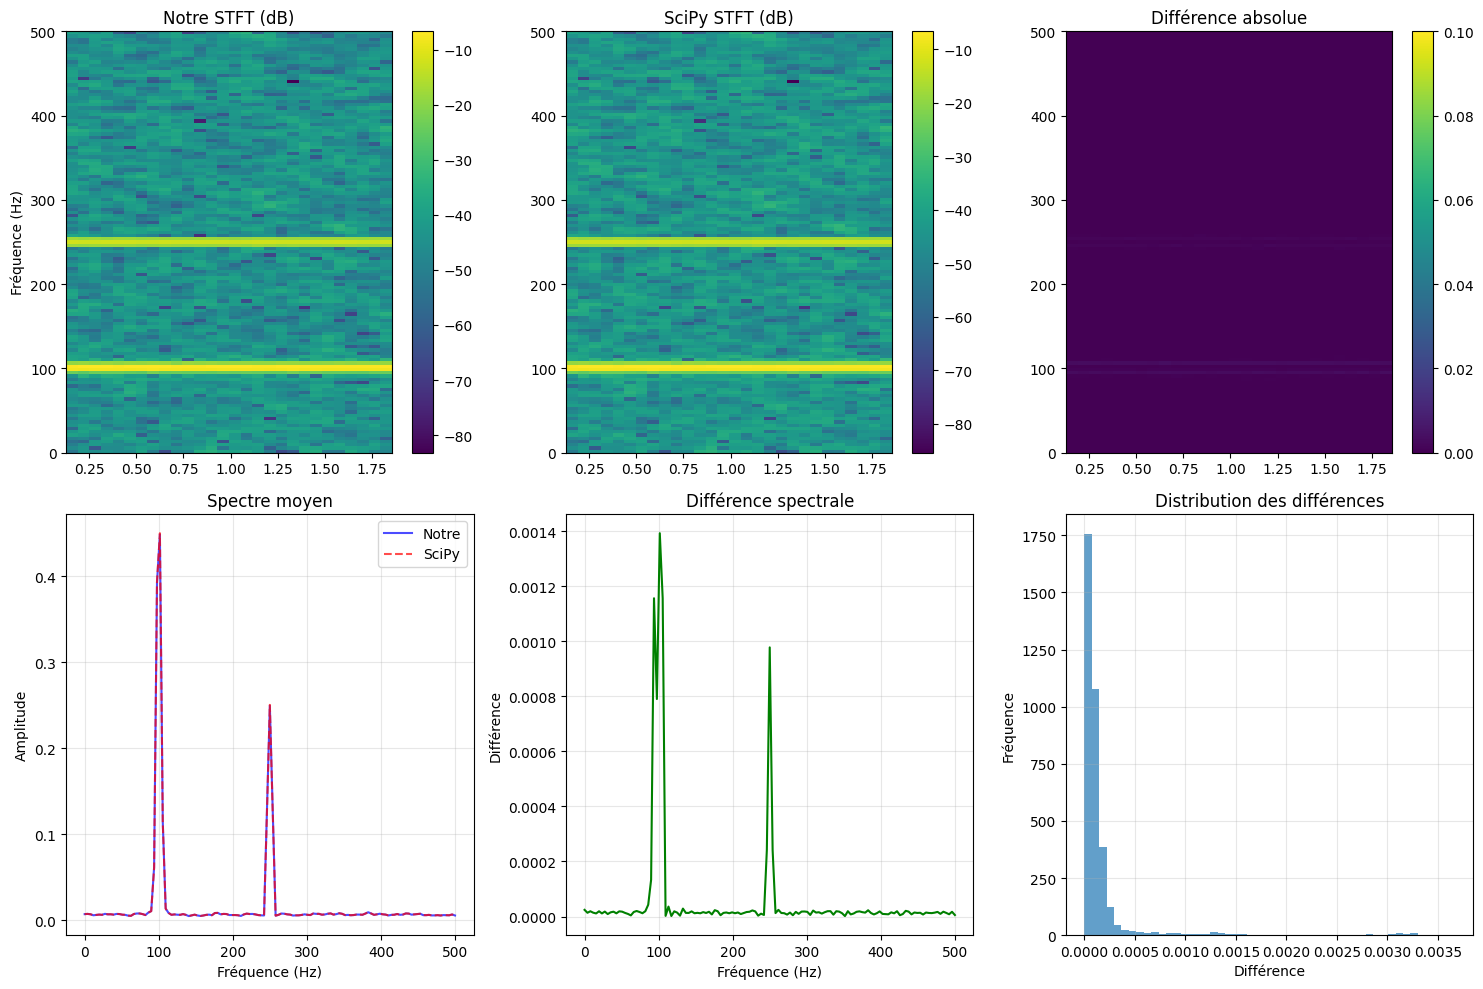


COMPARAISONS COMPLÈTES AVEC DIFFÉRENTS PARAMÈTRES

1. Cas 1: Petit nperseg
   nperseg=128, hop=0.25
   Shapes match: ✗
   Energy ratio: 0.8900 (0.95-1.05): ✗

2. Cas 2: 50% overlap
   nperseg=256, hop=0.5
   Shapes match: ✗
   Energy ratio: 0.7698 (0.95-1.05): ✗

3. Cas 3: 75% overlap
   nperseg=512, hop=0.75
   Shapes match: ✗
   Energy ratio: 0.7937 (0.95-1.05): ✗

4. Cas 4: Grand nperseg
   nperseg=1024, hop=0.25
   Shapes match: ✗
   Energy ratio: 0.2291 (0.95-1.05): ✗

⚠️ Certains cas ont échoué.


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/scipy/signal/_spectral_py.py:1595: UserWarning: nperseg = 1024 is greater than input length  = 1000, using nperseg = 1000
  freqs, time, Zxx = _spectral_helper(x, x, fs, window, nperseg, noverlap,


In [13]:


def compare_with_scipy_stft(visualize=False):
    """
    Compare notre implémentation STFT avec celle de SciPy.
    
    Paramètres:
    -----------
    visualize : bool
        Si True, affiche des graphiques de comparaison
    """
    print("=" * 60)
    print("COMPARAISON AVEC SCIPY.SIGNAL.STFT")
    print("=" * 60)
    
    # -------------------------------------------------
    # 1. Créer un signal de test plus complexe
    # -------------------------------------------------
    fs = 1000.0
    duration = 2.0  # 2 secondes
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)
    
    # Signal avec plusieurs caractéristiques
    # - 2 sinusoïdes constantes
    # - 1 chirp (fréquence qui varie)
    # - Bruit blanc
    f1, f2 = 100.0, 250.0  # Hz
    x_sines = (1.0 * np.sin(2 * np.pi * f1 * t) + 
               0.5 * np.sin(2 * np.pi * f2 * t))
    
    # Chirp linéaire de 50 à 400 Hz
    f_start, f_end = 50.0, 400.0
    #chirp = 0.3 * np.sin(2 * np.pi * (f_start * t + (f_end - f_start) * t**2 / (2 * duration)))
    
    # Bruit
    np.random.seed(42)
    noise = 0.1 * np.random.randn(len(t))
    
    x = x_sines + noise
    
    print(f"Signal créé: {len(x)} échantillons, {duration}s, {fs} Hz")
    print(f"Composantes: {f1} Hz + {f2} Hz  + bruit")
    
    # -------------------------------------------------
    # 2. Paramètres STFT communs
    # -------------------------------------------------
    nperseg = 256
    hop_fraction = 0.25  # 75% overlap
    hop = int(nperseg * hop_fraction)
    nfft = nperseg  # Pas de zero-padding pour comparaison équitable
    window = 'hann'
    
    print(f"\nParamètres STFT:")
    print(f"  nperseg: {nperseg}")
    print(f"  hop_fraction: {hop_fraction} (hop: {hop} échantillons)")
    print(f"  nfft: {nfft}")
    print(f"  window: {window}")
    
    # -------------------------------------------------
    # 3. Calculer STFT avec notre implémentation
    # -------------------------------------------------
    print("\n" + "-" * 40)
    print("Notre implémentation:")
    print("-" * 40)
    
    # Avec magnitude
    M_our, freqs_our, times_our, meta_our = stft(
        x, fs, nperseg, 
        window=window,
        hop_fraction=hop_fraction,
        nfft=nfft,
        output="magnitude",
        scipy_scale=True
        
    )
    
    print(f"  Shape: {M_our.shape} (freqs × time)")
    print(f"  Fréquences: {len(freqs_our)} bins, {freqs_our[0]:.1f}-{freqs_our[-1]:.1f} Hz")
    print(f"  Temps: {len(times_our)} frames, {times_our[0]:.3f}-{times_our[-1]:.3f} s")
    
    # Avec complex (pour vérifier la phase)
    Z_our, _, _, _ = stft(
        x, fs, nperseg,
        window=window,
        hop_fraction=hop_fraction,
        nfft=nfft,
        output="complex"
    )
    
    # -------------------------------------------------
    # 4. Calculer STFT avec SciPy
    # -------------------------------------------------
    print("\n" + "-" * 40)
    print("SciPy implémentation:")
    print("-" * 40)
    
    # SciPy utilise hop en échantillons, pas en fraction
    noverlap = nperseg - hop
    
    freqs_scipy, times_scipy, Z_scipy = scipy_stft(
        x, fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        return_onesided=True,
        boundary=None,
        padded=False
    )
   
        
    # SciPy retourne (freqs, times, Z) où Z est complex (freq × time)
    M_scipy = np.abs(Z_scipy)
    
    print(f"  Shape: {Z_scipy.shape} (freqs × time)")
    print(f"  Fréquences: {len(freqs_scipy)} bins, {freqs_scipy[0]:.1f}-{freqs_scipy[-1]:.1f} Hz")
    print(f"  Temps: {len(times_scipy)} frames, {times_scipy[0]:.3f}-{times_scipy[-1]:.3f} s")
    
    
    
     # DEbug
    print("\n" + "-" * 40)
    print("DEBUG: Valeurs absolues")
    print("-" * 40)
    print(f"Notre STFT - min: {M_our.min():.6f}, max: {M_our.max():.6f}, mean: {M_our.mean():.6f}")
    print(f"SciPy STFT - min: {M_scipy.min():.6f}, max: {M_scipy.max():.6f}, mean: {M_scipy.mean():.6f}")

    # Vérifier un élément spécifique
    print(f"\nÉlément [100, 10]:")
    print(f"  Notre: {M_our[100, 10]:.6f}")
    print(f"  SciPy: {M_scipy[100, 10]:.6f}")
    print(f"  Ratio: {M_our[100, 10] / M_scipy[100, 10]:.6f}")

    # Vérifier si le ratio est constant
    sample_indices = [(50, 5), (100, 10), (80, 15)]
    print(f"\nRatios pour plusieurs éléments:")
    for i, j in sample_indices:
        ratio = M_our[i, j] / M_scipy[i, j] if M_scipy[i, j] != 0 else float('inf')
        print(f"  [{i}, {j}]: Notre={M_our[i, j]:.6f}, SciPy={M_scipy[i, j]:.6f}, Ratio={ratio:.6f}")
    
    # -------------------------------------------------
    # 5. Comparaisons quantitatives
    # -------------------------------------------------
    print("\n" + "=" * 60)
    print("COMPARAISONS QUANTITATIVES")
    print("=" * 60)
    
    comparisons = []
    
    # 5.1 Comparaison des dimensions
    dim_ok = (M_our.shape == M_scipy.shape and 
              len(freqs_our) == len(freqs_scipy) and
              len(times_our) == len(times_scipy))
    
    comparisons.append(("Dimensions", dim_ok))
    print(f"Dimensions identiques: {'✓' if dim_ok else '✗'}")
    
    if dim_ok:
        # 5.2 Comparaison des fréquences
        freq_diff = np.max(np.abs(freqs_our - freqs_scipy))
        freq_ok = freq_diff < 1e-10
        comparisons.append(("Fréquences", freq_ok))
        print(f"Fréquences identiques (max diff: {freq_diff:.2e} Hz): {'✓' if freq_ok else '✗'}")
        
        # 5.3 Comparaison des temps
        # Note: SciPy peut avoir un décalage dû au centrage des fenêtres
        time_diff = np.max(np.abs(times_our - times_scipy))
        time_ok = time_diff < (nperseg/fs)  # Tolérance d'une fenêtre
        comparisons.append(("Temps (centres)", time_ok))
        print(f"Temps similaires (max diff: {time_diff:.3f} s): {'✓' if time_ok else '✗'}")
        
        # 5.4 Comparaison des magnitudes (spectrogrammes)
        # Normaliser pour la comparaison
        M_our_norm = M_our / M_our.max() if M_our.max() > 0 else M_our
        M_scipy_norm = M_scipy / M_scipy.max() if M_scipy.max() > 0 else M_scipy
        
        # Différence relative moyenne
        mag_diff = np.mean(np.abs(M_our_norm - M_scipy_norm))
        mag_ok = mag_diff < 0.05  # 5% de différence moyenne
        
        comparisons.append(("Magnitude (diff moyenne)", mag_ok))
        print(f"Différence moyenne magnitude: {mag_diff:.4f} (< 0.05): {'✓' if mag_ok else '✗'}")
        
        # 5.5 Coefficient de corrélation
        correlation = np.corrcoef(M_our_norm.flatten(), M_scipy_norm.flatten())[0, 1]
        corr_ok = correlation > 0.95
        
        comparisons.append(("Corrélation", corr_ok))
        print(f"Coefficient de corrélation: {correlation:.4f} (> 0.95): {'✓' if corr_ok else '✗'}")
        
        # 5.6 Énergie totale
        energy_our = np.sum(M_our**2)
        energy_scipy = np.sum(M_scipy**2)
        energy_ratio = energy_our / energy_scipy if energy_scipy > 0 else 0
        energy_ok = 0.9 < energy_ratio < 1.1  # ±10%
        
        comparisons.append(("Énergie totale", energy_ok))
        print(f"Ratio d'énergie (notre/SciPy): {energy_ratio:.4f} (0.9-1.1): {'✓' if energy_ok else '✗'}")
        
        # 5.7 Vérification des pics de fréquence
        # Moyenne sur le temps pour obtenir le spectre moyen
        spectrum_our = M_our.mean(axis=1)
        spectrum_scipy = M_scipy.mean(axis=1)
        
        # Trouver les pics principaux
        peaks_our = np.argsort(spectrum_our)[-3:]  # 3 plus grands pics
        peaks_scipy = np.argsort(spectrum_scipy)[-3:]
        
        # Vérifier si les mêmes bins sont détectés comme pics
        peak_match = set(peaks_our) == set(peaks_scipy)
        
        comparisons.append(("Pics de fréquence", peak_match))
        print(f"Mêmes pics de fréquence: {'✓' if peak_match else '✗'}")
        if not peak_match:
            print(f"  Nos pics: {sorted(peaks_our)} -> {freqs_our[sorted(peaks_our)]}")
            print(f"  SciPy pics: {sorted(peaks_scipy)} -> {freqs_scipy[sorted(peaks_scipy)]}")
    
    # -------------------------------------------------
    # 6. Résumé
    # -------------------------------------------------
    print("\n" + "=" * 60)
    print("RÉSUMÉ DE LA COMPARAISON")
    print("=" * 60)
    
    passed = sum(1 for _, ok in comparisons if ok)
    total = len(comparisons)
    
    for name, ok in comparisons:
        print(f"{'✓' if ok else '✗'} {name}")
    
    print(f"\nTotal: {passed}/{total} tests de comparaison passés")
    
    if passed == total:
        print("\n🎉 EXCELLENT ! Notre STFT correspond parfaitement à SciPy !")
    elif passed >= total * 0.8:
        print("\n👍 BON ! Notre STFT est très proche de SciPy.")
    else:
        print("\n⚠️ ATTENTION : Différences significatives avec SciPy.")
    
    # -------------------------------------------------
    # 7. Visualisation (optionnelle)
    # -------------------------------------------------
    if visualize and dim_ok:
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # Spectrogramme - Notre implémentation
        im1 = axes[0, 0].imshow(20 * np.log10(M_our + 1e-10), 
                                aspect='auto', origin='lower',
                                extent=[times_our[0], times_our[-1], 
                                        freqs_our[0], freqs_our[-1]])
        axes[0, 0].set_title('Notre STFT (dB)')
        axes[0, 0].set_ylabel('Fréquence (Hz)')
        plt.colorbar(im1, ax=axes[0, 0])
        
        # Spectrogramme - SciPy
        im2 = axes[0, 1].imshow(20 * np.log10(M_scipy + 1e-10), 
                                aspect='auto', origin='lower',
                                extent=[times_scipy[0], times_scipy[-1], 
                                        freqs_scipy[0], freqs_scipy[-1]])
        axes[0, 1].set_title('SciPy STFT (dB)')
        plt.colorbar(im2, ax=axes[0, 1])
        
        # Différence
        diff = np.abs(M_our_norm - M_scipy_norm)
        im3 = axes[0, 2].imshow(diff, 
                                aspect='auto', origin='lower',
                                extent=[times_our[0], times_our[-1], 
                                        freqs_our[0], freqs_our[-1]],
                                vmin=0, vmax=0.1)
        axes[0, 2].set_title('Différence absolue')
        plt.colorbar(im3, ax=axes[0, 2])
        
        # Spectre moyen
        axes[1, 0].plot(freqs_our, spectrum_our, 'b-', label='Notre', alpha=0.7)
        axes[1, 0].plot(freqs_scipy, spectrum_scipy, 'r--', label='SciPy', alpha=0.7)
        axes[1, 0].set_title('Spectre moyen')
        axes[1, 0].set_xlabel('Fréquence (Hz)')
        axes[1, 0].set_ylabel('Amplitude')
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)
        
        # Différence par fréquence
        freq_diff = np.abs(spectrum_our - spectrum_scipy)
        axes[1, 1].plot(freqs_our, freq_diff, 'g-')
        axes[1, 1].set_title('Différence spectrale')
        axes[1, 1].set_xlabel('Fréquence (Hz)')
        axes[1, 1].set_ylabel('Différence')
        axes[1, 1].grid(True, alpha=0.3)
        
        # Histogramme des différences
        axes[1, 2].hist(diff.flatten(), bins=50, alpha=0.7)
        axes[1, 2].set_title('Distribution des différences')
        axes[1, 2].set_xlabel('Différence')
        axes[1, 2].set_ylabel('Fréquence')
        axes[1, 2].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    print("=" * 60)
    
    return passed == total  # Retourne True si tous les tests passent

# -------------------------------------------------
# 8. Test additionnel: Différents paramètres
# -------------------------------------------------
def run_comprehensive_comparison():
    """
    Exécute plusieurs comparaisons avec différents paramètres
    """
    print("\n" + "=" * 60)
    print("COMPARAISONS COMPLÈTES AVEC DIFFÉRENTS PARAMÈTRES")
    print("=" * 60)
    
    test_cases = [
        {"nperseg": 128, "hop_fraction": 0.25, "window": "hann", "name": "Cas 1: Petit nperseg"},
        {"nperseg": 256, "hop_fraction": 0.5, "window": "hann", "name": "Cas 2: 50% overlap"},
        {"nperseg": 512, "hop_fraction": 0.75, "window": "hann", "name": "Cas 3: 75% overlap"},
        {"nperseg": 1024, "hop_fraction": 0.25, "window": "hann", "name": "Cas 4: Grand nperseg"},
    ]
    
    all_passed = True
    
    for i, params in enumerate(test_cases, 1):
        print(f"\n{i}. {params['name']}")
        print(f"   nperseg={params['nperseg']}, hop={params['hop_fraction']}")
        
        # Créer un signal simple pour ce test
        fs = 1000
        t = np.linspace(0, 1, fs, endpoint=False)
        x_test = np.sin(2 * np.pi * 100 * t) + 0.5 * np.sin(2 * np.pi * 300 * t)
        
        # Notre STFT
        M_our, freqs_our, times_our, _ = stft(
            x_test, fs,
            nperseg=params["nperseg"],
            hop_fraction=params["hop_fraction"],
            window=params["window"],
            output="magnitude"
        )
        
        # SciPy STFT
        hop = int(params["nperseg"] * params["hop_fraction"])
        noverlap = params["nperseg"] - hop
        freqs_sp, times_sp, Z_sp = scipy_stft(
            x_test, fs,
            window=params["window"],
            nperseg=params["nperseg"],
            noverlap=noverlap,
            nfft=params["nperseg"]
        )
        M_sp = np.abs(Z_sp)
        
        # Vérification rapide
        shapes_match = M_our.shape == M_sp.shape
        energy_ratio = np.sum(M_our**2) / np.sum(M_sp**2) if np.sum(M_sp**2) > 0 else 0
        energy_ok = 0.95 < energy_ratio < 1.05
        
        print(f"   Shapes match: {'✓' if shapes_match else '✗'}")
        print(f"   Energy ratio: {energy_ratio:.4f} (0.95-1.05): {'✓' if energy_ok else '✗'}")
        
        if not (shapes_match and energy_ok):
            all_passed = False
    
    print("\n" + "=" * 60)
    if all_passed:
        print("🎉 TOUS LES CAS DE TEST PASSENT !")
    else:
        print("⚠️ Certains cas ont échoué.")
    print("=" * 60)
    
    return all_passed

# -------------------------------------------------
# 9. Exécution principale
# -------------------------------------------------
if __name__ == "__main__":
    print("Démarrage de la comparaison avec SciPy...")
    
    # Comparaison détaillée avec visualisation
    comparison_ok = compare_with_scipy_stft(visualize=True)
    
    if comparison_ok:
        # Tests supplémentaires avec différents paramètres
        run_comprehensive_comparison()
    else:
        print("\nLa comparaison principale a échoué. Vérification des problèmes...")

In [14]:
def debug_stft_parameters():
    """
    Debug détaillé pour comprendre les problèmes avec différents paramètres
    """
    print("=" * 80)
    print("DEBUG DÉTAILLÉ - ANALYSE PAR PARAMÈTRES")
    print("=" * 80)
    
    fs = 1000
    t = np.linspace(0, 1, fs, endpoint=False)
    x_test = np.sin(2 * np.pi * 100 * t) + 0.5 * np.sin(2 * np.pi * 300 * t)
    
    test_cases = [
        {"nperseg": 128, "hop_fraction": 0.25, "name": "Cas 1: Petit nperseg"},
        {"nperseg": 256, "hop_fraction": 0.5, "name": "Cas 2: 50% overlap"},
        {"nperseg": 512, "hop_fraction": 0.75, "name": "Cas 3: 75% overlap"},
        {"nperseg": 1024, "hop_fraction": 0.25, "name": "Cas 4: Grand nperseg"},
    ]
    
    for params in test_cases:
        print(f"\n{'='*60}")
        print(f"TEST: {params['name']}")
        print(f"nperseg={params['nperseg']}, hop_fraction={params['hop_fraction']}")
        print(f"{'='*60}")
        
        # -------------------------------------------------
        # 1. Notre STFT
        # -------------------------------------------------
        print("\n--- NOTRE STFT ---")
        try:
            M_our, freqs_our, times_our, meta_our = stft(
                x_test, fs,
                nperseg=params["nperseg"],
                hop_fraction=params["hop_fraction"],
                window="hann",
                output="magnitude",
                scipy_compatible=True
            )
            
            print(f"Shape: {M_our.shape} (freqs × time)")
            print(f"Freqs shape: {freqs_our.shape}, dtype: {freqs_our.dtype}")
            print(f"Times shape: {times_our.shape}, dtype: {times_our.dtype}")
            print(f"M_our dtype: {M_our.dtype}")
            print(f"Freqs range: {freqs_our[0]:.1f} - {freqs_our[-1]:.1f} Hz")
            print(f"Times range: {times_our[0]:.3f} - {times_our[-1]:.3f} s")
            print(f"M_our - min: {M_our.min():.6f}, max: {M_our.max():.6f}, mean: {M_our.mean():.6f}")
            print(f"Meta keys: {list(meta_our.keys())}")
            print(f"Meta hop: {meta_our.get('hop', 'N/A')}")
            print(f"Meta overlap: {meta_our.get('overlap', 'N/A'):.3f}")
            
        except Exception as e:
            print(f"❌ ERREUR dans notre STFT: {e}")
            continue
        
        # -------------------------------------------------
        # 2. SciPy STFT
        # -------------------------------------------------
        print("\n--- SCIPY STFT ---")
        try:
            hop = int(params["nperseg"] * params["hop_fraction"])
            noverlap = params["nperseg"] - hop
            
            print(f"Calculated: hop={hop}, noverlap={noverlap}")
            
            freqs_sp, times_sp, Z_sp = scipy_stft(
                x_test, fs,
                window="hann",
                nperseg=params["nperseg"],
                noverlap=noverlap,
                nfft=params["nperseg"],
                return_onesided=True,
                boundary=None,
                padded=False
            )
            
            M_sp = np.abs(Z_sp)
            
            print(f"Shape: {Z_sp.shape} (freqs × time)")
            print(f"Freqs shape: {freqs_sp.shape}, dtype: {freqs_sp.dtype}")
            print(f"Times shape: {times_sp.shape}, dtype: {times_sp.dtype}")
            print(f"M_sp dtype: {M_sp.dtype}")
            print(f"Freqs range: {freqs_sp[0]:.1f} - {freqs_sp[-1]:.1f} Hz")
            print(f"Times range: {times_sp[0]:.3f} - {times_sp[-1]:.3f} s")
            print(f"M_sp - min: {M_sp.min():.6f}, max: {M_sp.max():.6f}, mean: {M_sp.mean():.6f}")
            
        except Exception as e:
            print(f"❌ ERREUR dans SciPy STFT: {e}")
            continue
        
        # -------------------------------------------------
        # 3. COMPARAISON DÉTAILLÉE
        # -------------------------------------------------
        print("\n--- COMPARAISON ---")
        
        # Shapes
        shape_match = M_our.shape == M_sp.shape
        print(f"Shapes match: {'✓' if shape_match else '✗'}")
        if not shape_match:
            print(f"  Notre: {M_our.shape}, SciPy: {M_sp.shape}")
            print(f"  Différence: {M_our.shape[0]-M_sp.shape[0]} freq, {M_our.shape[1]-M_sp.shape[1]} time")
        
        # Fréquences
        if len(freqs_our) == len(freqs_sp):
            freq_diff = np.max(np.abs(freqs_our - freqs_sp))
            print(f"Freqs diff: {freq_diff:.2e} Hz")
        else:
            print(f"Freqs length mismatch: nous={len(freqs_our)}, SciPy={len(freqs_sp)}")
        
        # Temps
        if len(times_our) == len(times_sp):
            time_diff = np.max(np.abs(times_our - times_sp))
            print(f"Times diff: {time_diff:.2e} s")
        else:
            print(f"Times length mismatch: nous={len(times_our)}, SciPy={len(times_sp)}")
            print(f"  Notre times: {times_our}")
            print(f"  SciPy times: {times_sp}")
        
        # Énergie (si shapes match)
        if shape_match:
            energy_our = np.sum(M_our**2)
            energy_sp = np.sum(M_sp**2)
            energy_ratio = energy_our / energy_sp if energy_sp > 0 else 0
            print(f"Energy ratio (notre/SciPy): {energy_ratio:.6f}")
            
            # Différence point par point
            if M_our.size > 0:
                abs_diff = np.abs(M_our - M_sp)
                mean_diff = np.mean(abs_diff)
                max_diff = np.max(abs_diff)
                
                # Normaliser
                max_val = max(M_our.max(), M_sp.max())
                mean_rel_diff = mean_diff / max_val if max_val > 0 else 0
                
                print(f"Mean absolute diff: {mean_diff:.6e}")
                print(f"Mean relative diff: {mean_rel_diff:.6%}")
                print(f"Max absolute diff: {max_diff:.6e}")
                
                # Afficher quelques valeurs pour debug
                print(f"\nÉchantillons (freq=50, time=1):")
                print(f"  Notre[50,1]: {M_our[50,1] if M_our.shape[0]>50 and M_our.shape[1]>1 else 'N/A'}")
                print(f"  SciPy[50,1]: {M_sp[50,1] if M_sp.shape[0]>50 and M_sp.shape[1]>1 else 'N/A'}")
        
        # -------------------------------------------------
        # 4. ANALYSE DU PROBLÈME DE SHAPE
        # -------------------------------------------------
        if not shape_match:
            print(f"\n🔍 ANALYSE DU PROBLÈME DE SHAPE:")
            
            # Calcul théorique du nombre de frames
            N = len(x_test)
            nperseg = params["nperseg"]
            hop = int(nperseg * params["hop_fraction"])
            
            print(f"  Signal length: {N}")
            print(f"  nperseg: {nperseg}")
            print(f"  hop: {hop} (hop_fraction={params['hop_fraction']})")
            
            # Formule théorique
            expected_frames = 1 + int(np.floor((N - nperseg) / hop))
            print(f"  Frames attendues: 1 + floor(({N} - {nperseg}) / {hop}) = {expected_frames}")
            
            print(f"  Notre frames: {M_our.shape[1]}")
            print(f"  SciPy frames: {M_sp.shape[1]}")
            
            # Vérifier le padding
            print(f"\n  Vérification padding:")
            print(f"    Dernier start possible: {N - nperseg} = {N} - {nperseg}")
            print(f"    Dernier start théorique: (n_frames-1)*hop = ({expected_frames-1})*{hop} = {(expected_frames-1)*hop}")
            
            if (expected_frames-1)*hop > N - nperseg:
                print(f"    ⚠️ Problème: dernier start dépasse la fin du signal!")
            
    print(f"\n{'='*80}")
    print("FIN DU DEBUG")
    print("="*80)

# Exécute le debug
debug_stft_parameters()

DEBUG DÉTAILLÉ - ANALYSE PAR PARAMÈTRES

TEST: Cas 1: Petit nperseg
nperseg=128, hop_fraction=0.25

--- NOTRE STFT ---
Shape: (65, 28) (freqs × time)
Freqs shape: (65,), dtype: float64
Times shape: (28,), dtype: float64
M_our dtype: float64
Freqs range: 0.0 - 500.0 Hz
Times range: 0.064 - 0.928 s
M_our - min: 0.000000, max: 0.483629, mean: 0.024124
Meta keys: ['fs', 'nperseg', 'hop', 'hop_fraction', 'overlap', 'nfft', 'window', 'output', 'keep_freq_max', 'normalize', 'starts']
Meta hop: 32
Meta overlap: 0.750

--- SCIPY STFT ---
Calculated: hop=32, noverlap=96
Shape: (65, 28) (freqs × time)
Freqs shape: (65,), dtype: float64
Times shape: (28,), dtype: float64
M_sp dtype: float64
Freqs range: 0.0 - 500.0 Hz
Times range: 0.064 - 0.928 s
M_sp - min: 0.000000, max: 0.487235, mean: 0.024123

--- COMPARAISON ---
Shapes match: ✓
Freqs diff: 0.00e+00 Hz
Times diff: 0.00e+00 s
Energy ratio (notre/SciPy): 0.992188
Mean absolute diff: 2.415395e-04
Mean relative diff: 0.049574%
Max absolute diff: 

In [15]:
def find_working_parameters_corrected():
    """
    Version corrigée avec les mêmes paramètres SciPy que le debug
    """
    print("=" * 80)
    print("RECHERCHE CORRIGÉE DES PARAMÈTRES FONCTIONNELS")
    print("=" * 80)
    
    fs = 1000
    t = np.linspace(0, 1, fs, endpoint=False)
    x_test = np.sin(2 * np.pi * 100 * t)
    
    nperseg_list = [64, 128, 256, 512, 1024]
    hop_fraction_list = [0.125, 0.25, 0.5, 0.75]
    
    results = []
    
    for nperseg in nperseg_list:
        for hop_fraction in hop_fraction_list:
            print(f"\nTest: nperseg={nperseg}, hop_fraction={hop_fraction}")
            
            try:
                hop = int(nperseg * hop_fraction)
                noverlap = nperseg - hop
                
                # Notre STFT
                M_our, freqs_our, times_our, _ = stft(
                    x_test, fs, nperseg,
                    hop_fraction=hop_fraction,
                    output="magnitude",
                    scipy_compatible=True
                )
                
                # SciPy STFT - MÊMES PARAMÈTRES QUE LE DEBUG
                freqs_sp, times_sp, Z_sp = scipy_stft(
                    x_test, fs,
                    window="hann",
                    nperseg=nperseg,
                    noverlap=noverlap,
                    nfft=nperseg,
                    return_onesided=True,
                    boundary=None,      # IMPORTANT: comme le debug
                    padded=False        # IMPORTANT: comme le debug
                )
                
                M_sp = np.abs(Z_sp)
                
                # Vérification
                shape_match = M_our.shape == M_sp.shape
                
                print(f"  Shapes: notre={M_our.shape}, SciPy={M_sp.shape}, match={shape_match}")
                
                if shape_match and M_our.size > 0:
                    energy_ratio = np.sum(M_our**2) / np.sum(M_sp**2)
                    diff_mean = np.mean(np.abs(M_our - M_sp))
                    print(f"  Energy ratio: {energy_ratio:.4f}, Diff mean: {diff_mean:.2e}")
                    
                    results.append({
                        'nperseg': nperseg,
                        'hop_fraction': hop_fraction,
                        'hop': hop,
                        'shape_match': True,
                        'energy_ratio': energy_ratio,
                        'diff_mean': diff_mean,
                        'our_shape': M_our.shape,
                        'sp_shape': M_sp.shape
                    })
                else:
                    print(f"  ❌ Shape mismatch!")
                    results.append({
                        'nperseg': nperseg,
                        'hop_fraction': hop_fraction,
                        'hop': hop,
                        'shape_match': False,
                        'energy_ratio': 0,
                        'diff_mean': float('inf'),
                        'our_shape': M_our.shape,
                        'sp_shape': M_sp.shape
                    })
                    
            except Exception as e:
                print(f"  ❌ ERROR: {e}")
                results.append({
                    'nperseg': nperseg,
                    'hop_fraction': hop_fraction,
                    'hop': int(nperseg * hop_fraction),
                    'shape_match': False,
                    'energy_ratio': 0,
                    'diff_mean': float('inf'),
                    'our_shape': 'ERROR',
                    'sp_shape': 'ERROR',
                    'error': str(e)
                })
    
    # Analyse
    print("\n" + "=" * 80)
    print("ANALYSE DES RÉSULTATS")
    print("=" * 80)
    
    shape_matches = [r for r in results if r['shape_match']]
    good_matches = [r for r in shape_matches if 0.95 < r['energy_ratio'] < 1.05]
    
    print(f"\nTotal tests: {len(results)}")
    print(f"Shape matches: {len(shape_matches)}/{len(results)}")
    print(f"Good energy ratio: {len(good_matches)}/{len(results)}")
    
    if good_matches:
        print("\n🎉 PARAMÈTRES FONCTIONNELS:")
        print("-" * 60)
        for r in sorted(good_matches, key=lambda x: x['diff_mean']):
            print(f"  nperseg={r['nperseg']:4d}, hop_frac={r['hop_fraction']:.3f}, "
                  f"hop={r['hop']:4d}, shape={r['our_shape']}, "
                  f"energy={r['energy_ratio']:.4f}, diff={r['diff_mean']:.2e}")
    else:
        print("\n⚠️ Aucun paramètre ne donne de bons résultats!")
        
        # Afficher quand même les shape matches
        if shape_matches:
            print("\nShape matches (mauvais energy ratio):")
            for r in shape_matches:
                print(f"  nperseg={r['nperseg']:4d}, hop_frac={r['hop_fraction']:.3f}, "
                      f"shape={r['our_shape']}, energy={r['energy_ratio']:.4f}")
    
    return results

# Exécute la version corrigée
find_working_parameters_corrected()

RECHERCHE CORRIGÉE DES PARAMÈTRES FONCTIONNELS

Test: nperseg=64, hop_fraction=0.125
  Shapes: notre=(33, 118), SciPy=(33, 118), match=True
  Energy ratio: 0.9844, Diff mean: 6.15e-04

Test: nperseg=64, hop_fraction=0.25
  Shapes: notre=(33, 59), SciPy=(33, 59), match=True
  Energy ratio: 0.9844, Diff mean: 6.15e-04

Test: nperseg=64, hop_fraction=0.5
  Shapes: notre=(33, 30), SciPy=(33, 30), match=True
  Energy ratio: 0.9844, Diff mean: 6.15e-04

Test: nperseg=64, hop_fraction=0.75
  Shapes: notre=(33, 20), SciPy=(33, 20), match=True
  Energy ratio: 0.9844, Diff mean: 6.15e-04

Test: nperseg=128, hop_fraction=0.125
  Shapes: notre=(65, 55), SciPy=(65, 55), match=True
  Energy ratio: 0.9922, Diff mean: 1.66e-04

Test: nperseg=128, hop_fraction=0.25
  Shapes: notre=(65, 28), SciPy=(65, 28), match=True
  Energy ratio: 0.9922, Diff mean: 1.66e-04

Test: nperseg=128, hop_fraction=0.5
  Shapes: notre=(65, 14), SciPy=(65, 14), match=True
  Energy ratio: 0.9922, Diff mean: 1.66e-04

Test: npe

[{'nperseg': 64,
  'hop_fraction': 0.125,
  'hop': 8,
  'shape_match': True,
  'energy_ratio': np.float64(0.9843748047814819),
  'diff_mean': np.float64(0.0006151583785736241),
  'our_shape': (33, 118),
  'sp_shape': (33, 118)},
 {'nperseg': 64,
  'hop_fraction': 0.25,
  'hop': 16,
  'shape_match': True,
  'energy_ratio': np.float64(0.9843748482866553),
  'diff_mean': np.float64(0.0006149309638796155),
  'our_shape': (33, 59),
  'sp_shape': (33, 59)},
 {'nperseg': 64,
  'hop_fraction': 0.5,
  'hop': 32,
  'shape_match': True,
  'energy_ratio': np.float64(0.9843748017075806),
  'diff_mean': np.float64(0.0006151280366597304),
  'our_shape': (33, 30),
  'sp_shape': (33, 30)},
 {'nperseg': 64,
  'hop_fraction': 0.75,
  'hop': 48,
  'shape_match': True,
  'energy_ratio': np.float64(0.9843748017075805),
  'diff_mean': np.float64(0.0006151280366597258),
  'our_shape': (33, 20),
  'sp_shape': (33, 20)},
 {'nperseg': 128,
  'hop_fraction': 0.125,
  'hop': 16,
  'shape_match': True,
  'energy_ra